# E1b. Is the brain-only occlusion signal just the shape of the hole? (29 Oct 2026)

**Why.** In E1, blanking the lesion and its 10 mm ring left the ensemble at AUROC 0.677 (0.636-0.716). A zero-filled hole
still shows the lesion's size, shape and position, and the network's crop is built around the tumour (bounding box plus
16 voxels, rescaled to 128^3), so the remaining "brain" is a thin shell of peritumoural tissue around a tumour-shaped hole.
The paper therefore lists this as a limitation. E1b tests it directly.

**Design (pre-declared).** The three members' held-out checkpoints (the ones behind the paper's out-of-fold predictions)
score every development patient under six inputs; the ensemble is the mean of the three members.

| Condition | Input | What it isolates |
|---|---|---|
| original | unchanged | reproduction check (must match the saved OOF probabilities within 0.01) |
| brain_only | lesion + ring set to 0 | E1 condition, reproduction check (must match E1 within 0.01) |
| silhouette | brain outside the lesion + ring set to +1 SD; hole and background 0 | hole and brain outline only, no tissue |
| silhouette_neg | the same with -1 SD | the constant's sign should not matter |
| brain_only_inpainted | hole filled from the surrounding brain + matched fine noise | tissue kept, silhouette contrast largely removed |
| tumour_silhouette | lesion + ring set to +1 SD, all else 0 | tumour shape and extent only (compare with E1's tumour_ring_only 0.859) |

CPU analyses on the same patients:
- **Lesion geometry model:** 11 shape, size and position features of the lesion in the crop (log volume, crop spacing,
  elongation, sphericity, solidity, components, centroid offset, ...), L2 logistic, repeated 5x5 site x class CV as in the paper.
- **Does brain_only add to geometry?** CV AUROC of geometry (+ silhouette logit) with and without the brain_only logit
  (paired bootstrap), and the AUROC of the brain_only logit's cross-fitted residual after regression on geometry.
- Age-matched AUROC (the published matched sample) and within-class age correlation for every condition.

**Reading rules (fixed before the results).**
- **R1, shape explains it:** silhouette AUROC within 0.05 of brain_only, *or* geometry CV AUROC within 0.03 of it, and the
  brain_only logit adds nothing beyond geometry + silhouette (CI includes 0). Then the brain-only residual is lesion
  geometry, not brain tissue.
- **R2, tissue carries information:** brain_only adds beyond geometry + silhouette (CI excludes 0), the inpainted input
  stays within 0.05 of brain_only, and inpainted beats silhouette (CI excludes 0).
- **R3, mixed:** anything else; report both numbers.
- Either way, occluded inputs are out of distribution: only ranking (AUROC) is interpreted. Inpainting leaves mass effect
  and a smoother patch, so R2 still says "peritumoural tissue", not "distant brain".

**Run time (RTX 5080, estimate):** about 1-1.5 h. Mostly CPU work (inpainting, ~1 s per patient per member) plus 6
forward passes per patient per member. Resumes per member and fold if interrupted.

## 1. Configuration (same paths as the 27 Oct GPU notebook)

In [1]:
from pathlib import Path
import os, sys
PROJECT = Path.cwd()                                                        # RadGenome project folder (this notebook here)
PKG = Path.home() / 'Downloads' / 'RadGenome_ISBI_package_v6'               # unzipped v6 package (results/, code/)
CPU_DIR = PROJECT / 'isbi_cpu_reanalyses_27oct'                             # common.py rebuilds the 1,393-patient frame
DL_OUT = Path.home() / 'Downloads' / 'outputs'
BASE = DL_OUT / 'clinical_experiments'                                      # member runs (CA42, CA44, MC42)
OUT = PROJECT / 'outputs' / 'isbi_gpu_27oct'                                # where E1 wrote e1_occlusion/
INPUT_CACHE = DL_OUT / 'novelty_input_cache'
PATH_REMAP = {r'C:\Users\claks\Downloads\PKG - UCSF-PDGM Version 5\UCSF-PDGM-v5': r'C:\Users\claks\Downloads\UCSF-PDGM'}
DEVICE = 'cuda'
N_BOOT, SEED = 2000, 20261021
CHUNK = 3                      # inputs per forward pass; lower to 2 (or 1) on CUDA out-of-memory

## 2. Setup and prerequisites

In [2]:
import json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
warnings.filterwarnings('ignore')
for p in (PROJECT, CPU_DIR):
    if str(p) not in sys.path: sys.path.insert(0, str(p))
os.environ['RG_PKG'] = str(PKG); os.environ['RG_DL_OUT'] = str(DL_OUT); os.environ['RG_RG_OUT'] = str(PROJECT / 'outputs')
import isbi_gpu_experiments as X
import isbi_e1b_shape_control as S
from common import build
from sklearn.metrics import roc_auc_score

E1_DIR, E1B_DIR = OUT / 'e1_occlusion', OUT / 'e1b_shape_control'
MASK_DIR = E1_DIR / 'crop_masks'
E1B_DIR.mkdir(parents=True, exist_ok=True)
e1_parts = sorted(E1_DIR.glob('occlusion_*_fold*.npz'))
assert len(e1_parts) == 15, f'E1 outputs not found in {E1_DIR} (expected 15 member-fold files, found {len(e1_parts)})'
print(f'E1 files: {len(e1_parts)} | cached crop masks: {len(list(MASK_DIR.glob("*.npz")))}')

G = build()
Z = G['Z']
print(f'Analysis cohort: {len(Z)} patients, {int(Z.y.sum())} IDH-mutant')
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (this will be very slow)')
def md_table(df, nd=3):
    f = lambda v: f'{v:.{nd}f}' if isinstance(v, (float, np.floating)) else str(v)
    return '\n'.join(['| ' + ' | '.join(map(str, df.columns)) + ' |', '|' + '---|' * len(df.columns)] +
                     ['| ' + ' | '.join(f(v) for v in r) + ' |' for r in df.itertuples(index=False)])

E1 files: 15 | cached crop masks: 1432
Analysis cohort: 1393 patients, 186 IDH-mutant
GPU: NVIDIA GeForce RTX 5080 Laptop GPU


## 3. Inference (resumable)

In [3]:
from ensemble_oof_xrai import cohort
cases = [c for c in cohort(runs=[BASE / m for m in X.MEMBERS], threshold=X.THRESHOLD) if c['label'] is not None]
print(f'{len(cases)} development patients | members: {[X.SHORT[m] for m in X.MEMBERS]}')
t0 = time.time()
S.run_shape_occlusion(cases, E1B_DIR, MASK_DIR, INPUT_CACHE, device=DEVICE, path_remap=PATH_REMAP, chunk=CHUNK)
print(f'E1b inference finished in {(time.time() - t0) / 60:.1f} min')

1432 development patients | members: ['CA42', 'CA44', 'MC42']
    v2_reference_seed42 fold 1: 50/287 | 38s
    v2_reference_seed42 fold 1: 100/287 | 74s
    v2_reference_seed42 fold 1: 150/287 | 108s
    v2_reference_seed42 fold 1: 200/287 | 143s
    v2_reference_seed42 fold 1: 250/287 | 178s
  v2_reference_seed42 fold 1: 287 cases in 205s | original vs saved OOF: max |diff| 0.0002, 0 above 0.01
    v2_reference_seed42 fold 2: 50/286 | 37s
    v2_reference_seed42 fold 2: 100/286 | 73s
    v2_reference_seed42 fold 2: 150/286 | 108s
    v2_reference_seed42 fold 2: 200/286 | 143s
    v2_reference_seed42 fold 2: 250/286 | 178s
  v2_reference_seed42 fold 2: 286 cases in 204s | original vs saved OOF: max |diff| 0.0003, 0 above 0.01
    v2_reference_seed42 fold 3: 50/286 | 37s
    v2_reference_seed42 fold 3: 100/286 | 73s
    v2_reference_seed42 fold 3: 150/286 | 109s
    v2_reference_seed42 fold 3: 200/286 | 145s
    v2_reference_seed42 fold 3: 250/286 | 181s
  v2_reference_seed42 fold 3: 28

## 4. Reproduction checks (stop here if either fails)

In [4]:
long, ens = S.load_shape(E1B_DIR)
e1_long, e1_ens = X.load_occlusion(E1_DIR)
chk = long.merge(e1_long[['patient_id', 'member', 'brain_only']].rename(columns={'brain_only': 'brain_only_E1'}), on=['patient_id', 'member'])
d_oof, d_e1 = (long.original - long.saved_oof).abs(), (chk.brain_only - chk.brain_only_E1).abs()
print(f'original vs saved OOF: max |diff| {d_oof.max():.4f} ({int((d_oof > .01).sum())} of {len(d_oof)} above 0.01)')
print(f'brain_only vs E1:      max |diff| {d_e1.max():.4f} ({int((d_e1 > .01).sum())} of {len(d_e1)} above 0.01)')
assert d_oof.max() < 0.01 and d_e1.max() < 0.01, 'Reproduction failed: do not interpret E1b until this is explained'

original vs saved OOF: max |diff| 0.0006 (0 of 4296 above 0.01)
brain_only vs E1:      max |diff| 0.0001 (0 of 4296 above 0.01)


## 5. Lesion geometry in the crop (CPU, cached)

In [5]:
gpath = E1B_DIR / 'lesion_geometry.csv'
if gpath.exists():
    geom = pd.read_csv(gpath)
else:
    t0 = time.time(); geom = S.geometry_features(MASK_DIR, ens.patient_id.tolist()); geom.to_csv(gpath, index=False)
    print(f'geometry for {len(geom)} patients in {time.time() - t0:.0f}s')
display(geom[S.GEOMETRY].describe().T.round(3))

geometry for 1432 patients in 58s


,count,mean,std,min,25%,50%,75%,max
log_lesion_ml,1423.0,4.148,0.898,-1.913,3.640,4.330,4.805,5.844
log_keep_ml,1423.0,5.448,0.588,2.458,5.078,5.542,5.888,6.762
log_crop_spacing,1423.0,-0.147,0.225,-1.131,-0.280,-0.126,0.012,0.517
lesion_crop_fraction,1423.0,0.053,0.023,0.001,0.036,0.053,0.070,0.130
keep_crop_fraction,1423.0,0.182,0.051,0.017,0.149,0.187,0.218,0.302
elong_2_1,1423.0,0.730,0.140,0.206,0.647,0.749,0.834,0.984
elong_3_1,1423.0,0.566,0.128,0.155,0.487,0.574,0.655,0.891
sphericity,1423.0,0.428,0.086,0.167,0.367,0.429,0.491,0.649
solidity_bbox,1423.0,0.279,0.094,0.008,0.221,0.291,0.346,0.533
n_components,1423.0,3.586,5.651,1.000,1.000,2.000,4.000,74.000


## 6. Results

In [6]:
res, diffs, uni, info, D = S.analyse_shape(ens, e1_ens, Z, geom, n_boot=N_BOOT, seed=SEED)
print(json.dumps(info, indent=1))
show = ['score', 'n', 'mutant', 'auroc', 'auroc_ci', 'auroc_age_matched', 'auroc_age_matched_ci', 'rho_age_wildtype', 'rho_age_mutant']
display(res[show].round(3)); display(diffs.round(3)); display(uni.round(3))
for line in S.verdict(res, diffs, info): print(line)
res.to_csv(E1B_DIR / 'E1b_auroc.csv', index=False); diffs.to_csv(E1B_DIR / 'E1b_paired_differences.csv', index=False)
uni.to_csv(E1B_DIR / 'E1b_geometry_univariable.csv', index=False)
D.to_csv(E1B_DIR / 'E1b_per_patient.csv', index=False)

{
 "analysis_patients": 1393,
 "mutant": 186,
 "max_abs_original_minus_saved_oof": 0.00017824458579224212,
 "max_abs_brain_only_minus_E1": 2.6186307271358622e-05,
 "cv_r2_brain_only_logit_from_geometry": 0.18880968483348604,
 "cv_r2_silhouette_logit_from_geometry": 0.2684925181814769,
 "matched_sets": 96,
 "matched_patients": 358,
 "median_hole_share_of_brain": 0.3037848905483123
}


,score,n,mutant,auroc,auroc_ci,auroc_age_matched,auroc_age_matched_ci,rho_age_wildtype,rho_age_mutant
0,original,1393,186,0.926,0.904-0.945,0.900,0.862-0.930,-0.088,-0.178
1,brain_only,1393,186,0.677,0.636-0.716,0.668,0.611-0.725,-0.051,-0.015
2,silhouette,1393,186,0.580,0.542-0.620,0.571,0.505-0.633,-0.094,-0.027
3,silhouette_neg,1393,186,0.523,0.477-0.566,0.554,0.480-0.625,0.127,0.012
4,brain_only_inpainted,1393,186,0.678,0.637-0.716,0.650,0.581-0.721,-0.057,0.005
5,tumour_silhouette,1393,186,0.525,0.481-0.568,0.500,0.440-0.564,-0.049,-0.118
6,tumour_ring_only,1393,186,0.859,0.827-0.888,0.838,0.790-0.881,-0.044,-0.231
7,Lesion geometry (CV),1393,186,0.792,0.756-0.825,0.726,0.663-0.781,NaN,NaN
8,Geometry + brain_only logit (CV),1393,186,0.807,0.771-0.839,0.759,0.699-0.812,NaN,NaN
9,Geometry + silhouette logit (CV),1393,186,0.792,0.756-0.825,0.729,0.666-0.785,NaN,NaN


,comparison,delta_auroc,ci,delta_age_matched,ci_age_matched
0,silhouette minus brain_only,-0.098,-0.136 to -0.057,-0.097,-0.157 to -0.038
1,silhouette_neg minus brain_only,-0.155,-0.210 to -0.096,-0.114,-0.211 to -0.022
2,brain_only_inpainted minus brain_only,0.001,-0.032 to +0.034,-0.018,-0.073 to +0.041
3,brain_only_inpainted minus silhouette,0.098,+0.051 to +0.143,0.080,+0.003 to +0.162
4,tumour_silhouette minus tumour_ring_only,-0.333,-0.377 to -0.291,-0.337,-0.409 to -0.268
5,Geometry + brain_only logit (CV) minus Lesion ...,0.015,+0.004 to +0.026,0.033,+0.011 to +0.055
6,Geometry + silhouette + brain_only logits (CV)...,0.014,+0.003 to +0.024,0.030,+0.009 to +0.051
7,Geometry + brain_only_inpainted logit (CV) min...,0.013,+0.004 to +0.022,0.023,+0.004 to +0.043
8,brain_only minus Lesion geometry (CV),-0.114,-0.161 to -0.070,-0.058,-0.133 to +0.020


,feature,auroc_oriented,spearman_with_brain_only_logit
0,log_lesion_ml,0.517,0.096
1,log_keep_ml,0.566,0.030
2,log_crop_spacing,0.598,-0.164
3,lesion_crop_fraction,0.591,0.295
4,keep_crop_fraction,0.597,0.285
5,elong_2_1,0.605,0.168
6,elong_3_1,0.650,0.255
7,sphericity,0.790,0.220
8,solidity_bbox,0.713,0.326
9,n_components,0.659,-0.213


R3: mixed. Geometry explains part of the brain-only signal and tissue part of it. Paper: report both numbers in one sentence and keep a shortened limitation.
Check: the two silhouette constants disagree by > 0.05; report both, read the silhouette result as fill-sensitive.


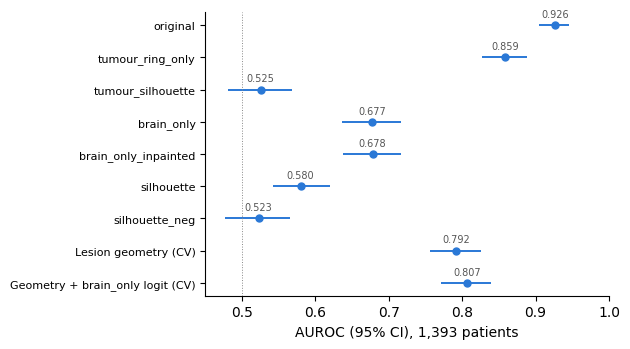

In [7]:
order = ['original', 'tumour_ring_only', 'tumour_silhouette', 'brain_only', 'brain_only_inpainted', 'silhouette',
         'silhouette_neg', 'Lesion geometry (CV)', 'Geometry + brain_only logit (CV)']
r = res.set_index('score').loc[order]
lo = r.auroc_ci.str.split('-').str[0].astype(float); hi = r.auroc_ci.str.split('-').str[1].astype(float)
fig, ax = plt.subplots(figsize=(6.4, 3.6)); ys = np.arange(len(order))[::-1]
ax.hlines(ys, lo, hi, color='#2a78d6', lw=1.4); ax.plot(r.auroc, ys, 'o', color='#2a78d6', ms=5)
for yv, a in zip(ys, r.auroc): ax.text(a, yv + .25, f'{a:.3f}', ha='center', fontsize=7, color='#555')
ax.axvline(.5, color='#888', lw=.7, ls=':'); ax.set_yticks(ys); ax.set_yticklabels(order, fontsize=8)
ax.set_xlim(.45, 1); ax.set_xlabel('AUROC (95% CI), 1,393 patients'); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(E1B_DIR / 'E1b_shape_control.png', dpi=200); plt.show()

## 7. Report and the sentence for the paper

In [8]:
a = res.set_index('score'); d = diffs.set_index('comparison')
inc = d.loc['Geometry + silhouette + brain_only logits (CV) minus Geometry + silhouette logit (CV)']
sentence = (f"With the lesion and margin blanked the ensemble kept AUROC {a.loc['brain_only','auroc']:.3f}; a silhouette of the hole "
            f"alone gave {a.loc['silhouette','auroc']:.3f}, a lesion-geometry model {a.loc['Lesion geometry (CV)','auroc']:.3f}, and "
            f"inpainting the hole from surrounding brain {a.loc['brain_only_inpainted','auroc']:.3f}; the brain-only output added "
            f"{inc.delta_auroc:+.3f} ({inc.ci}) beyond geometry and silhouette. The tumour's silhouette alone scored "
            f"{a.loc['tumour_silhouette','auroc']:.3f} (tumour + margin with texture: {a.loc['tumour_ring_only','auroc']:.3f}).")
lines = ['# E1b. Shape control for the brain-only occlusion', '', f'Run {time.strftime("%Y-%m-%d %H:%M")} on '
         f'{torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}.', '', 'Info: ' + json.dumps(info), '',
         '## Verdict (pre-declared reading rules)', ''] + [f'- {v}' for v in S.verdict(res, diffs, info)] + [
         '', '## Draft sentence', '', sentence, '',
         '## AUROC by score', '', md_table(res[show]), '', '## Paired differences', '', md_table(diffs), '',
         '## Geometry features: univariable AUROC and correlation with the brain-only logit', '', md_table(uni), '',
         '## Conditions', ''] + [f'- **{k}**: {v}' for k, v in S.CONDITION_TEXT.items()] + [
         '', 'Occluded inputs are out of distribution; only AUROC is interpreted. Inpainting leaves mass effect and a smoother patch.']
(E1B_DIR / 'REPORT.md').write_text('\n'.join(lines), encoding='utf-8')
print(sentence); print('Wrote', E1B_DIR / 'REPORT.md')

With the lesion and margin blanked the ensemble kept AUROC 0.677; a silhouette of the hole alone gave 0.580, a lesion-geometry model 0.792, and inpainting the hole from surrounding brain 0.678; the brain-only output added +0.014 (+0.003 to +0.024) beyond geometry and silhouette. The tumour's silhouette alone scored 0.525 (tumour + margin with texture: 0.859).
Wrote c:\Users\claks\OneDrive\文件\ChatGPT\RadGenome\outputs\isbi_gpu_27oct\e1b_shape_control\REPORT.md
